# 일본 공모 ST 94건 (5·14회차)

`labs/data-lab/japan_st_offerings.tsv`(BOOSTRY 공모 ST 목록, 2021-04-27 ~ 2026-10-27)와 `start_listings.tsv`(ODX START 취급 종목)를 읽어 슬라이드의 숫자를 다시 만든다. 금액 단위는 백만 엔.

In [1]:
import sys, pathlib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
LABS = pathlib.Path.cwd().parent / "labs"
for f in ["Noto Sans CJK KR", "AppleGothic", "Malgun Gothic", "NanumGothic"]:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = f; break
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
                     "axes.unicode_minus": False})
ACC, GREY = "#2F5D8C", "#8E8C87"
import csv
from collections import Counter, defaultdict
rows = list(csv.DictReader(open(LABS / "data-lab" / "japan_st_offerings.tsv", encoding="utf-8"), delimiter="\t"))
amt = np.array([float(r["amount_mn_jpy"]) for r in rows])
print(len(rows), "건, 합계", round(amt.sum()/100, 1), "억 엔")
print("평균", round(amt.mean()/100, 1), "억 엔 / 중앙값", round(np.median(amt)/100, 1), "억 엔 / 최대", round(amt.max()/100, 1), "억 엔")

94 건, 합계 4075.2 억 엔
평균 43.4 억 엔 / 중앙값 22.3 억 엔 / 최대 314.1 억 엔


## 1. 회계연도별 발행

일본 회계연도는 4월에 시작한다. FY2026은 10월 27일까지다.

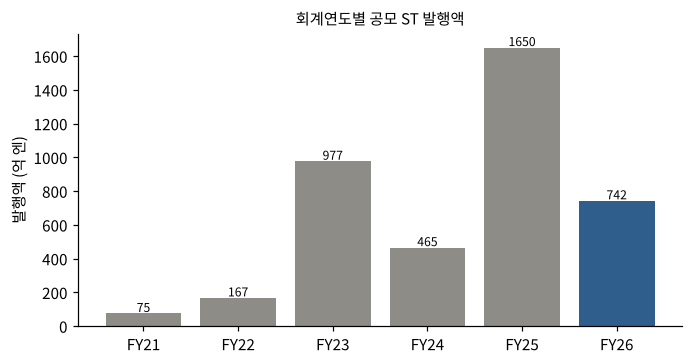

In [2]:
def fy(d):
    y, m = int(d[:4]), int(d[5:7]); return y if m >= 4 else y - 1
by = defaultdict(float)
for r, a in zip(rows, amt): by[fy(r["issue_date"])] += a
ys = sorted(by); vals = [by[y]/100 for y in ys]
fig, ax = plt.subplots(figsize=(6.4, 3.4))
bars = ax.bar([f"FY{str(y)[2:]}" for y in ys], vals, color=[GREY]*(len(ys)-1) + [ACC])
ax.bar_label(bars, fmt="%.0f", fontsize=8); ax.set_ylabel("발행액 (억 엔)")
ax.set_title("회계연도별 공모 ST 발행액", fontsize=10); plt.tight_layout()

## 2. 플랫폼 집중

발행액 기준 플랫폼 비중과 HHI. 두 플랫폼(Progmat, ibet for Fin)이 96%다.

In [3]:
plat = defaultdict(float)
for r, a in zip(rows, amt): plat[r["platform"]] += a
tot = sum(plat.values())
share = sorted(((k, v/tot) for k, v in plat.items()), key=lambda x: -x[1])
for k, s in share: print(f"{k:16s} {s:6.1%}")
hhi = sum((100*s)**2 for _, s in share)
print("HHI", round(hhi), " 등가 플랫폼 수", round(1e4/hhi, 2))

Progmat           58.1%
ibet for Fin      38.0%
Securitize         1.2%
Loadstar Chain     0.9%
OwnerShip          0.9%
Hash DasH          0.4%
ADDX               0.4%
HHI 4826  등가 플랫폼 수 2.07


## 3. 크기 분포

평균이 중앙값의 두 배 가까이 된다. 오른쪽으로 긴 꼬리다(문제집 5.2).

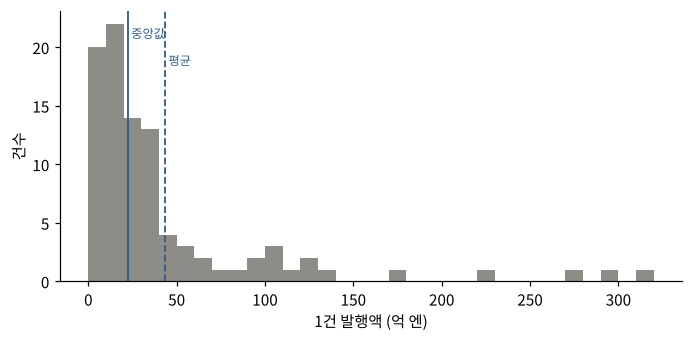

In [4]:
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.hist(amt/100, bins=np.arange(0, 330, 10), color=GREY)
ax.axvline(np.median(amt)/100, color=ACC, lw=1.2); ax.axvline(amt.mean()/100, color=ACC, lw=1.2, ls="--")
ax.text(np.median(amt)/100 + 2, ax.get_ylim()[1]*.9, "중앙값", color=ACC, fontsize=8)
ax.text(amt.mean()/100 + 2, ax.get_ylim()[1]*.8, "평균", color=ACC, fontsize=8)
ax.set_xlabel("1건 발행액 (억 엔)"); ax.set_ylabel("건수"); plt.tight_layout()

## 4. 2차 시장: START

94건 중 START에서 거래되는 것은 10건이다. 발행일부터 거래 시작일까지의 기간(일)도 본다.

In [5]:
from datetime import date
st = list(csv.DictReader(open(LABS / "data-lab" / "start_listings.tsv", encoding="utf-8"), delimiter="\t"))
later = [x for x in st if x["start_date"] > "2026-10-28"]
print(len(st), "건 START 목록, 그중", len(later), "건은 2026-10-28 이후 시작 예정")
listed = [r for r in rows if r["start"].strip() in ("〇", "◯")]
print("목록에서 START 표시:", len(listed), "건, 발행액", round(sum(float(r['amount_mn_jpy']) for r in listed)/100, 1), "억 엔")
for s in st[:12]: print(s["start_date"], s["short_name"], s["platform"])

11 건 START 목록, 그중 1 건은 2026-10-28 이후 시작 예정
목록에서 START 표시: 10 건, 발행액 940.5 억 엔
2023-12-25 ＫＤＸＳＴドーミーイン神戸元町 ibet for Fin
2023-12-25 いちごＲＴ芝公園・東新宿他４件 Progmat
2024-05-24 いちごＲＴ西麻布・代々木他５件 Progmat
2024-09-06 ＫＤＸＳＴ名古屋栄ビル Progmat
2024-09-18 トーセイＳＴ３市ヶ谷 Progmat
2024-10-25 いちごＲＴ仲之町・小日向他５件 ibet for Fin
2025-12-05 三井物産Ｇ三重イオンタウン鈴鹿 ibet for Fin
2026-03-25 ＳＢＩＨＤ　第１回ＳＴ社債 ibet for Fin
2026-10-01 ＫＪＲＭＲＴ汐留シティセンター Progmat
2026-10-01 ＫＤＸＳＴ　Ｗ　ＯＳＡＫＡ Progmat
2026-11-02 ＫＤＸＳＴ大阪レジ東西都市開発 Progmat


출처: BOOSTRY 일본 시큐리티 토큰 시장 대시보드(2026-10-28 열람), ODX START 신규 취급 종목 페이지(2026-10-28 확인). 집계 코드는 `labs/data-lab/analyze_japan.py`와 같다.